# Kwadaso Weather Classification AI

This notebook demonstrates a simple **K-Nearest Neighbours (K-NN)** supervised classification model for weather conditions in Kwadaso, Kumasi.

**Important:** The included CSV contains **sample/simulated data for demonstration**, not verified historical Kwadaso observations. Replace it with real local weather records before presenting it as real data.

In [12]:
import csv
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

print("Kwadaso Weather AI is ready.")

Kwadaso Weather AI is ready.


In [13]:
# Load the weather dataset

data = []

with open('kwadaso_weather_sample.csv', 'r', encoding='utf-8') as file:
    reader = csv.DictReader(file)

    for row in reader:
        data.append({
            'temperature': float(row['temperature']),
            'humidity': float(row['humidity']),
            'wind_speed': float(row['wind_speed']),
            'rainfall': float(row['rainfall']),
            'weather': row['weather']
        })

print("Number of records:", len(data))

print("\nFirst 5 records:")
for row in data[:5]:
    print(row)

Number of records: 48

First 5 records:
{'temperature': 31.2, 'humidity': 58.0, 'wind_speed': 7.5, 'rainfall': 0.0, 'weather': 'Sunny'}
{'temperature': 30.5, 'humidity': 62.0, 'wind_speed': 8.2, 'rainfall': 0.0, 'weather': 'Sunny'}
{'temperature': 32.1, 'humidity': 55.0, 'wind_speed': 6.8, 'rainfall': 0.0, 'weather': 'Sunny'}
{'temperature': 29.8, 'humidity': 65.0, 'wind_speed': 9.1, 'rainfall': 0.0, 'weather': 'Sunny'}
{'temperature': 31.5, 'humidity': 60.0, 'wind_speed': 7.2, 'rainfall': 0.0, 'weather': 'Sunny'}


## 1. Prepare the training data

The model uses four features: temperature, humidity, wind speed and rainfall. The target is the weather class.

In [14]:
# Define the input features and target

features = [
    'temperature',
    'humidity',
    'wind_speed',
    'rainfall'
]

X = [[row[f] for f in features] for row in data]
y = [row['weather'] for row in data]

print("Input features:", features)
print("Weather classes:", sorted(set(y)))

Input features: ['temperature', 'humidity', 'wind_speed', 'rainfall']
Weather classes: ['Cloudy', 'Rainy', 'Sunny']


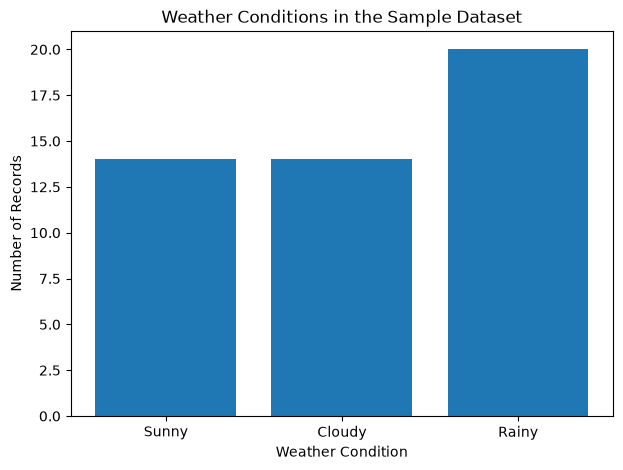

In [15]:
# Count the number of records in each weather class

weather_counts = Counter(y)

plt.figure(figsize=(7, 5))

plt.bar(
    weather_counts.keys(),
    weather_counts.values()
)

plt.xlabel("Weather Condition")
plt.ylabel("Number of Records")
plt.title("Weather Conditions in the Sample Dataset")

plt.show()

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 38
Testing records: 10


## 2. K-NN model

K-NN compares a new weather record with the closest records in the training data and uses the majority class of its nearest neighbours.

In [17]:
def distance(a, b):
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b)))

def predict(new_values, k=3):
    distances = []
    for values, label in zip(X, y):
        distances.append((distance(new_values, values), label))
    distances.sort(key=lambda item: item[0])
    nearest_labels = [label for _, label in distances[:k]]
    return Counter(nearest_labels).most_common(1)[0][0]

print('K-NN model created with k = 3')# Create the K-Nearest Neighbours model

model = KNeighborsClassifier(n_neighbors=3)

# Train the model
model.fit(X_train, y_train)

print("K-NN model trained successfully.")
print("Number of neighbours (K): 3")

K-NN model created with k = 3
K-NN model trained successfully.
Number of neighbours (K): 3


In [18]:
# Make predictions using the unseen testing data

y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Cloudy       1.00      1.00      1.00         3
       Rainy       1.00      1.00      1.00         4
       Sunny       1.00      1.00      1.00         3

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



In [19]:
# Enter new weather information

temperature = float(input("Temperature (°C): "))
humidity = float(input("Humidity (%): "))
wind_speed = float(input("Wind speed (km/h): "))
rainfall = float(input("Rainfall (mm): "))

# Put the values into the same format used during training
new_weather = [[
    temperature,
    humidity,
    wind_speed,
    rainfall
]]

# Make the prediction
prediction = model.predict(new_weather)[0]

print("\nPredicted weather for Kwadaso:", prediction)


Predicted weather for Kwadaso: Sunny


In [22]:
!pip install matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Users\UNIVERSAL PRESTIGE\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip
